# 03 · Models, uncertainty and stocking decisions

**Question:** how much of each item will each Texas store sell over the next 4 weeks, how confident are we, and how much should we stock?

## Executive summary

The summary below is generated from `reports/metrics.json`. Every number in it is computed by the pipeline; none are typed in by hand.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from forecast import PROCESSED_DIR, REPO_ROOT
from forecast.backtest import add_week_index
from forecast.plotting import (GRID, INK_SECONDARY, METHOD_COLORS, METHOD_LABELS, METHOD_MARKERS,
                               MUTED, apply_style)

apply_style()
REPORTS = REPO_ROOT / "reports"
metrics = json.loads((REPORTS / "metrics.json").read_text())
board = pd.read_csv(REPORTS / "model_scoreboard.csv")
coverage = pd.read_csv(REPORTS / "coverage.csv")
importance = pd.read_csv(REPORTS / "feature_importance.csv")
inventory = pd.read_csv(REPORTS / "inventory.csv")
tradeoff = pd.read_csv(REPORTS / "inventory_tradeoff.csv")
METHODS = ["naive", "ma4", "snaive", "hgbr", "xgb", "p50"]

def score(method, level, stat="wape"):
    row = board[(board.group_by == "overall") & (board.method == method) & (board.level == level)]
    return float(row[stat].iloc[0])

def by_volume_band(fc, origins):
    """WAPE and bias per volume band (series ranked by their 4-week average)."""
    s = fc[fc.origin_idx.isin(origins)].copy()
    level = s.groupby(["item_id", "store_id"], observed=True)["ma4"].transform("mean")
    s["band"] = pd.qcut(level, [0, .5, .9, .99, 1], labels=["bottom 50%", "50-90%", "90-99%", "top 1%"])
    rows = {}
    for band, x in s.groupby("band", observed=True):
        rows[band] = {"share of units": x.actual.sum() / s.actual.sum(),
                      **{f"WAPE {m}": (x[m] - x.actual).abs().sum() / x.actual.sum() for m in ["ma4", "hgbr", "xgb"]},
                      **{f"bias {m}": (x[m] - x.actual).sum() / x.actual.sum() for m in ["ma4", "hgbr"]},
                      "P90 coverage": (x.actual <= x.p90).mean()}
    return pd.DataFrame(rows).T

fc = pd.read_parquet(REPO_ROOT / "models" / "backtest_forecasts.parquet")
fold_origins = [o["origin_idx"] for o in metrics["origins"]]
bands = by_volume_band(fc, fold_origins)
top = bands.loc["top 1%"]
mid_share = bands.loc[["50-90%", "90-99%"], "share of units"].sum()

inv = metrics["inventory"]
pol = {p["policy"]: p for p in inv["policies"]}
cov = {c["method"]: c["coverage"] for c in metrics["models"]["p90_coverage"]}
savings = inv["saving_by_target_fill_rate"]
lo, hi = savings[0], savings[-1]
I, D = "item-store-week", "dept-store-week"

print(f"""STOCKING (the business result)
- Stocking to the model's P90 forecast reaches a {pol['model']['fill_rate']:.1%} unit fill rate with
  {pol['model']['avg_on_hand']:.1f} units on hand per item-store; the baseline policy (4-week average plus
  historical error) reaches {pol['baseline']['fill_rate']:.1%} with {pol['baseline']['avg_on_hand']:.1f}.
- At the SAME fill rate, the model policy needs {inv['inventory_saving_at_equal_fill_rate']:.0%} less inventory.
  The saving grows with the service level targeted: {lo['inventory_saving']:.0%} at {lo['fill_rate']:.0%} fill rate,
  {hi['inventory_saving']:.0%} at {hi['fill_rate']:.0%}.
- Stockout weeks: {pol['model']['stockout_week_share']:.1%} of item-store-weeks (model) vs
  {pol['baseline']['stockout_week_share']:.1%} (baseline).

ACCURACY (where the model wins and where it doesn't)
- Department x store x week: ML WAPE {score('hgbr', D):.3f} (HGBR) / {score('xgb', D):.3f} (XGBoost) vs
  {score('ma4', D):.3f} for the best baseline (4-week moving average).
- Item x store x week: HGBR {score('hgbr', I):.3f} is level with the moving average ({score('ma4', I):.3f});
  XGBoost is better at {score('xgb', I):.3f}. Much of a single item's week-to-week variation is randomness
  that no feature predicts.
- Known weakness: on the top 1% of item-stores by volume ({top['share of units']:.0%} of units), HGBR's WAPE is
  {top['WAPE hgbr']:.3f} vs {top['WAPE ma4']:.3f} for the moving average. HGBR bins each feature, and the
  biggest sellers share one bin (section 1b). HGBR beats the moving average in the middle bands
  (50-99% by volume, {mid_share:.0%} of units) and is slightly worse on the smallest half of item-stores.
- Bias: HGBR {score('hgbr', I, 'bias'):+.1%} vs moving average {score('ma4', I, 'bias'):+.1%} (negative = under-forecast).

CONFIDENCE
- The model's P90 covers {cov['p90']:.1%} of actual weeks (target 90%); the baseline's P90 covers {cov['baseline_p90']:.1%}.
  Better-calibrated P90s are what turn into less stock for the same service.""")

STOCKING (the business result)
- Stocking to the model's P90 forecast reaches a 97.2% unit fill rate with
  12.8 units on hand per item-store; the baseline policy (4-week average plus
  historical error) reaches 96.5% with 12.7.
- At the SAME fill rate, the model policy needs 11% less inventory.
  The saving grows with the service level targeted: 6% at 95% fill rate,
  14% at 98%.
- Stockout weeks: 4.5% of item-store-weeks (model) vs
  6.2% (baseline).

ACCURACY (where the model wins and where it doesn't)
- Department x store x week: ML WAPE 0.060 (HGBR) / 0.059 (XGBoost) vs
  0.073 for the best baseline (4-week moving average).
- Item x store x week: HGBR 0.404 is level with the moving average (0.402);
  XGBoost is better at 0.390. Much of a single item's week-to-week variation is randomness
  that no feature predicts.
- Known weakness: on the top 1% of item-stores by volume (18% of units), HGBR's WAPE is
  0.286 vs 0.209 for the moving average. HGBR bins each feature, and the
  bigge

**Caveats, up front:**
- **Sales ≠ demand.** M5 has no inventory data. Simulated "demand" is historical sales, which were themselves limited by the stock the store had.
- **Summed weekly P90s.** The order-up-to level adds two weekly P90s, which overstates the true 2-week P90. Both policies use the same rule, so the comparison is fair, but both carry some extra stock.
- **The equal-fill-rate comparison** scales both policies' stock levels on the test window itself. It is a way to compare the two, not a tuned policy.
- **Four forecast origins** (Jan–Apr 2016) cover a single spring. Results could differ around the holidays.

## 1. Accuracy: models vs. baselines

All methods are scored on the same rows: 4 origins × 4 horizons × every item-store. WAPE is the size of the errors relative to volume (lower is better). Bias is positive when forecasts are too high.

In [2]:
table = (board[board.group_by == "overall"]
         .pivot(index="method", columns="level", values=["wape", "bias"]).loc[METHODS])
table.index = [METHOD_LABELS.get(m, m) if m != "p50" else "HGBR median (P50)" for m in table.index]
table.style.format("{:.3f}").set_caption("All origins pooled")

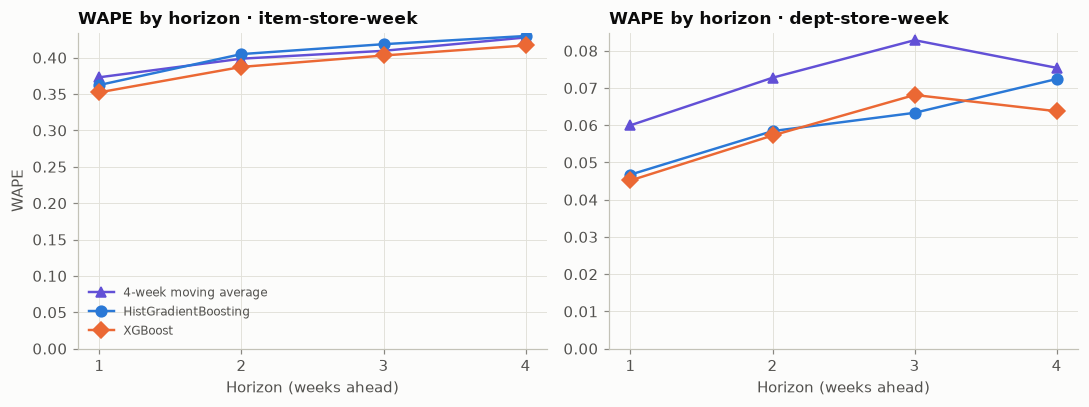

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
show = ["ma4", "hgbr", "xgb"]
for ax, level in zip(axes, [I, D]):
    part = board[(board.group_by == "h") & (board.level == level)]
    for m in show:
        s = part[part.method == m].sort_values("group")
        ax.plot(s["group"].astype(int), s["wape"], color=METHOD_COLORS[m], marker=METHOD_MARKERS[m],
                markersize=7, label=METHOD_LABELS[m])
    ax.set_title(f"WAPE by horizon · {level}", fontsize=11)
    ax.set_xlabel("Horizon (weeks ahead)")
    ax.set_xticks([1, 2, 3, 4])
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("WAPE")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

by_h = board[board.group_by == "h"].pivot_table(index=["level", "group"], columns="method", values="wape")[METHODS]
by_h.style.format("{:.3f}").set_caption("WAPE by horizon (table view)")

**Reading it:**
- **Department level:** both ML models beat the best baseline at every horizon. Summed over a department, the model's better reading of the level and the calendar adds up, and random item noise cancels out.
- **Item level:** the main HGBR model wins one week ahead, but is level with or slightly behind the moving average at 2–4 weeks. XGBoost beats the moving average at every horizon.
- **Why HGBR trails XGBoost** (hypotheses, not yet tested):
  - XGBoost uses `item_id`; HGBR can't, because of its 255-category limit.
  - XGBoost's default learning rate is higher, so HGBR at 100 iterations may be underfit.
- **Why the item-level gains are small:** a single item's sales in a single week are dominated by randomness no feature can predict. The recent average already captures most of what is predictable.

In [4]:
order = ["smooth", "erratic", "intermittent", "lumpy"]
dt = board[board.group_by == "demand_type"]
wape_dt = dt.pivot(index="group", columns="method", values="wape").loc[order, METHODS]
bias_dt = dt.pivot(index="group", columns="method", values="bias").loc[order, METHODS]
pd.concat({"WAPE": wape_dt, "bias": bias_dt}, axis=1).style.format("{:.3f}").set_caption(
    "Item-store-week by demand type")

**Reading it:**
- The models' clearest item-level gains are on **intermittent** series, which sell in some weeks and not others, and on **erratic** series.
- On **intermittent and lumpy** series, the HGBR model also removes most of the under-forecasting bias the baselines have. XGBoost does so on lumpy series only.
- On **smooth** series, the moving average is already hard to beat.

### 1b. Where the main model loses: the top sellers

The overall item-level score hides a split. Series are ranked by their 4-week average sales and grouped into volume bands:

In [5]:
bands.style.format({c: "{:.1%}" if c in ("share of units", "P90 coverage") or c.startswith("bias") else "{:.3f}"
                    for c in bands.columns})

,share of units,WAPE ma4,WAPE hgbr,WAPE xgb,bias ma4,bias hgbr,P90 coverage
bottom 50%,10.4%,0.764,0.782,0.759,-9.6%,7.7%,90.7%
50-90%,36.6%,0.467,0.445,0.448,-2.4%,-2.0%,88.4%
90-99%,35.1%,0.327,0.310,0.312,-1.5%,-2.8%,88.5%
top 1%,17.9%,0.209,0.286,0.210,-3.0%,-4.0%,85.3%


In [6]:
import joblib
from forecast.models import HGBR_FEATURES

hgbr_h1 = joblib.load(REPO_ROOT / "models" / "hgbr_h1.joblib")
edges = hgbr_h1._bin_mapper.bin_thresholds_[HGBR_FEATURES.index("roll_mean_4")]
at_last = fc[(fc.origin_idx == fold_origins[-1]) & (fc.h == 1)]
in_top_bin = at_last[at_last.ma4 > edges[-1]]
print(f"HGBR splits roll_mean_4 into {len(edges) + 1} bins; the top bin starts at {edges[-1]:.0f} units/week.")
print(f"At the last origin, {len(in_top_bin)} item-stores fall in that top bin, with 4-week averages from "
      f"{in_top_bin.ma4.min():.0f} to {in_top_bin.ma4.max():.0f} units/week.")

HGBR splits roll_mean_4 into 95 bins; the top bin starts at 160 units/week.
At the last origin, 27 item-stores fall in that top bin, with 4-week averages from 162 to 545 units/week.


**Reading it:**
- **HGBR beats the moving average in the middle bands (50–99% by volume), which hold most of the units.** It is slightly worse on the smallest half of item-stores, where sales are mostly zeros and ones. It is far worse on the top 1%: a handful of very high-volume item-stores that weigh heavily in WAPE. That top band is where its item-level shortfall comes from.
- **The cause is how HGBR works.** Before building trees, it sorts every feature into at most 255 bins. Recent sales are skewed: most item-stores sell a few units a week, a few sell hundreds. So the bins are fine-grained at the low end, and one bin holds everything above a threshold. Inside that bin, the model can't tell an item selling 200 a week from one selling 500.
- **XGBoost does fine here** because it knows each item through `item_id`, which HGBR can't use (255-category limit).
- **The likely fix:** model sales *relative to each series' own level* (e.g. sales ÷ its 13-week average), then multiply back. Every series then lives on the same scale, so the bins stop clipping the top. This is a candidate for the next step (see section 7). It changes the target, so it needs its own leakage tests.

## 2. Mean or median? Why the "best WAPE" model isn't used

WAPE adds up absolute errors, and the forecast that minimizes absolute error is the **median**. For a series that sells nothing in most weeks, the median is 0. So the median model (P50) gets a good item-level WAPE by forecasting low. In total, though, it under-forecasts badly, and at department level it is the worst method. The Poisson model predicts the **mean**, so the units add up. For stocking and planning totals, that matters more than a slightly better item-level WAPE.

In [7]:
mm = pd.DataFrame({m: {"WAPE item": score(m, I), "WAPE dept": score(m, D), "bias": score(m, I, "bias")}
                   for m in ["hgbr", "p50"]}).T
mm.index = ["HGBR Poisson (mean)", "HGBR P50 (median)"]
mm.style.format("{:.3f}")

,WAPE item,WAPE dept,bias
HGBR Poisson (mean),0.404,0.060,-0.016
HGBR P50 (median),0.390,0.118,-0.111


## 3. Confidence: is the P90 really a P90?

A P90 forecast should be at or above the actual sales in about 90% of weeks. Below 90% means the "safety" level is too low, and stockouts will be more common than planned.

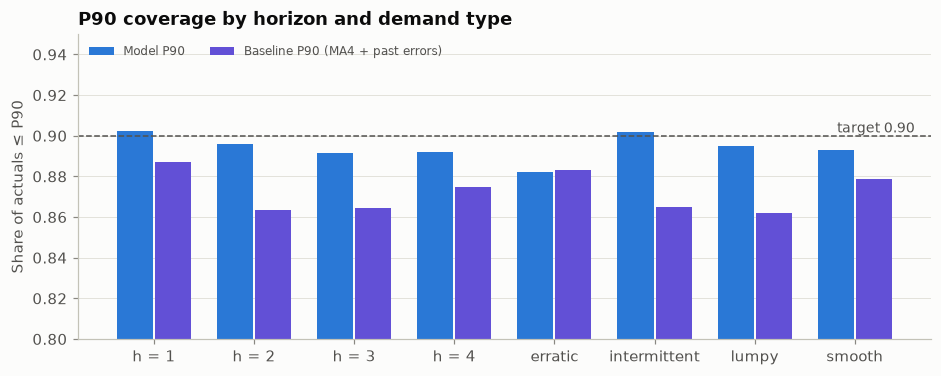

In [8]:
c = coverage[coverage.group_by.isin(["h", "demand_type"])].copy()
c["label"] = np.where(c.group_by == "h", "h = " + c.group.astype(str), c.group)
labels = list(dict.fromkeys(c["label"]))
x = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(10, 3.6))
for i, (m, name, color) in enumerate([("p90", "Model P90", METHOD_COLORS["hgbr"]),
                                       ("baseline_p90", "Baseline P90 (MA4 + past errors)", METHOD_COLORS["ma4"])]):
    vals = c[c.method == m].set_index("label").loc[labels, "coverage"]
    ax.bar(x + (i - 0.5) * 0.38, vals, 0.36, color=color, label=name)
ax.axhline(0.9, color=INK_SECONDARY, linestyle="--", linewidth=1)
ax.text(len(labels) - 0.4, 0.9, "target 0.90", va="bottom", ha="right", color=INK_SECONDARY, fontsize=9)
ax.set_xticks(x, labels)
ax.set_ylim(0.8, 0.95)
ax.set_ylabel("Share of actuals ≤ P90")
ax.set_title("P90 coverage by horizon and demand type")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", fontsize=8, ncols=2)
plt.show()

coverage.pivot(index=["group_by", "group"], columns="method", values="coverage").style.format("{:.3f}")

**Reading it:** the model's P90 sits close to 90% for every horizon and demand type. The baseline's P90 falls short in most groups, most of all on intermittent and lumpy series; on erratic series the two are about equal. A P90 built from past errors reacts slowly to how uncertain a series is *right now*; the quantile model reads that from recent volatility and the zero-sales share.

## 4. What drives the forecast?

**Permutation importance:** shuffle one feature in the test rows and measure how much the error (MAE) gets worse. A big increase means the model relies on that feature. It is computed for the HGBR model at 1 and 4 weeks ahead, averaged over the four origins.

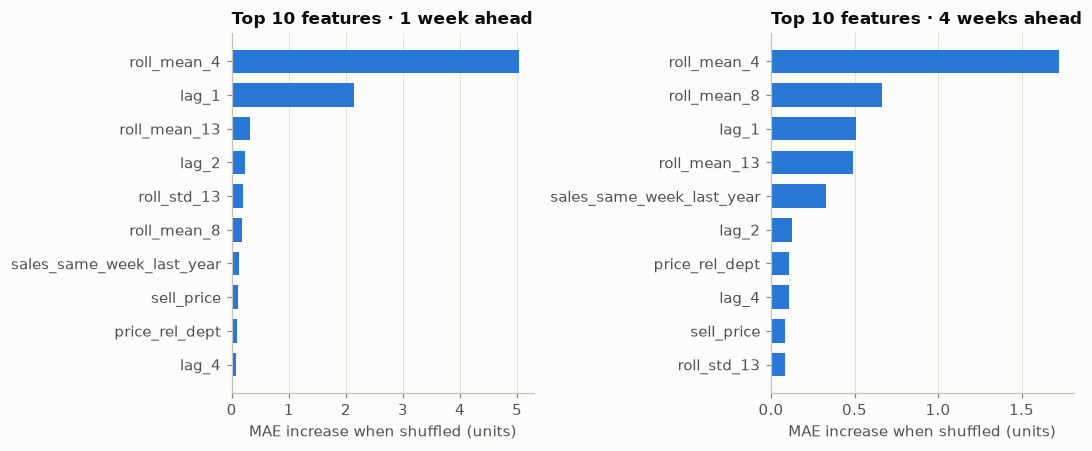

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=False)
for ax, h in zip(axes, [1, 4]):
    top = importance[importance.h == h].nlargest(10, "importance").iloc[::-1]
    ax.barh(top["feature"], top["importance"], color=METHOD_COLORS["hgbr"], height=0.7)
    ax.set_title(f"Top 10 features · {h} week{'s' if h > 1 else ''} ahead", fontsize=11)
    ax.set_xlabel("MAE increase when shuffled (units)")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Reading it:**
- The **recent 4-week average dominates.** The model is essentially a smart refinement of a moving average: it adjusts it for last week's sales, longer-term levels, last year's same week, price and the calendar.
- Further ahead, the longer windows and same-week-last-year carry relatively more weight than last week's sales.
- Price and calendar features matter, but much less. That fits a period (Jan–Apr) without major holidays.

## 5. Stocking decisions: the inventory simulation

**The policy, simulated for every item-store over the 16 test weeks:**
- **Review:** every week, the store orders up to a level *S*.
- **Order-up-to level:** *S* = the P90 forecast for next week + the P90 for the week after (1 week lead time + 1 week until the next review).
- **Lost sales:** demand that can't be served from stock is lost.
- **Start:** stock begins at *S*.

The two policies differ only in which P90 they use: the model's, or the baseline's (moving average + historical error).

In [10]:
inventory.style.format({"fill_rate": "{:.1%}", "avg_on_hand": "{:.2f}",
                        "stockout_week_share": "{:.1%}", "lost_units": "{:,.0f}"}).hide(axis="index")

policy,group,fill_rate,avg_on_hand,stockout_week_share,lost_units
model,all,97.2%,12.79,4.5%,"35,400"
model,smooth,97.7%,16.16,4.7%,"20,868"
model,erratic,95.5%,18.22,5.7%,"4,960"
model,intermittent,96.6%,7.94,3.9%,"7,246"
model,lumpy,96.1%,9.86,4.6%,"2,326"
baseline,all,96.5%,12.65,6.2%,"44,625"
baseline,smooth,97.3%,16.47,5.8%,"24,200"
baseline,erratic,95.6%,19.38,5.8%,"4,782"
baseline,intermittent,94.3%,7.38,6.5%,"12,035"
baseline,lumpy,93.9%,8.24,7.3%,"3,608"


As simulated, the model policy has both a higher fill rate *and* slightly more stock, so neither number alone says which is better. To compare fairly, every order-up-to level is scaled by a factor *k*. That traces how much stock each policy needs for a given fill rate. The curve further up and to the left is better: more service for the same stock.

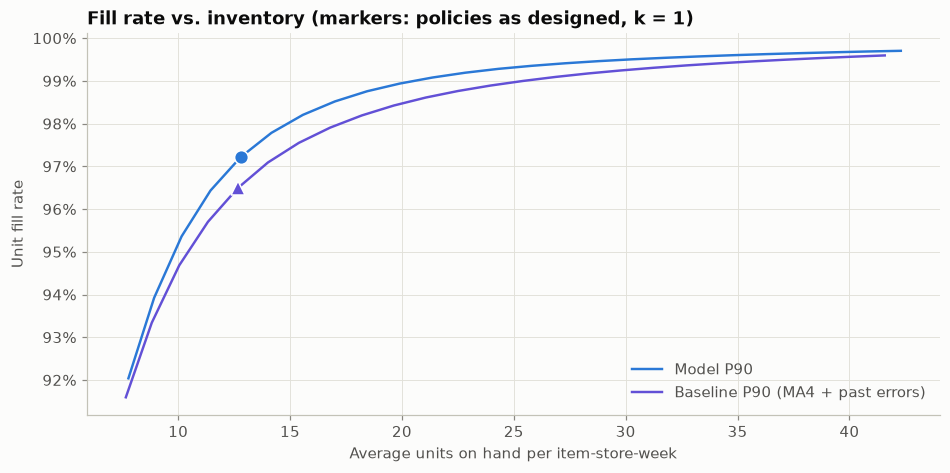

fill_rate,model_avg_on_hand,baseline_avg_on_hand,inventory_saving
95%,9.84,10.45,5.8%
96%,10.92,11.83,7.7%
97%,12.42,13.81,10.1%
98%,14.89,17.26,13.7%


In [11]:
policy_style = {"model": ("Model P90", METHOD_COLORS["hgbr"], "o"),
                "baseline": ("Baseline P90 (MA4 + past errors)", METHOD_COLORS["ma4"], "^")}
fig, ax = plt.subplots(figsize=(10, 4.5))
for p, (name, color, marker) in policy_style.items():
    cur = tradeoff[(tradeoff.policy == p) & (tradeoff.fill_rate >= 0.9)]
    ax.plot(cur["avg_on_hand"], cur["fill_rate"], color=color, label=name)
    k1 = tradeoff[(tradeoff.policy == p) & (tradeoff.k == 1)]
    ax.plot(k1["avg_on_hand"], k1["fill_rate"], marker=marker, markersize=9, color=color,
            markeredgecolor="white", linestyle="none")
ax.set_xlabel("Average units on hand per item-store-week")
ax.set_ylabel("Unit fill rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Fill rate vs. inventory (markers: policies as designed, k = 1)")
ax.legend(loc="lower right")
plt.show()

pd.DataFrame(inv["saving_by_target_fill_rate"]).style.format(
    {"fill_rate": "{:.0%}", "model_avg_on_hand": "{:.2f}", "baseline_avg_on_hand": "{:.2f}",
     "inventory_saving": "{:.1%}"}).hide(axis="index").set_caption("Inventory needed at equal fill rate")

**Reading it:**
- At every fill rate from 90% upward, the model's curve lies above the baseline's: the same service with less stock.
- The gap widens at higher service levels, where a well-calibrated P90 matters most. The baseline's under-covering P90 has to be inflated a lot to stop stockouts.
- **By demand type** (first table in this section), the two policies differ in kind:
  - **Smooth and erratic items:** the model policy is better on both counts: at least the same fill rate with less stock.
  - **Intermittent and lumpy items:** the model holds *more* stock and earns a clearly higher fill rate. The baseline under-stocks these items, as its low P90 coverage predicted.

## 6. One forecast, as the app will show it

The app shows the forecast made at the last origin (week starting 2016-04-16) for the 4 weeks after it, next to what actually sold. The example is the highest-volume item at TX_2.

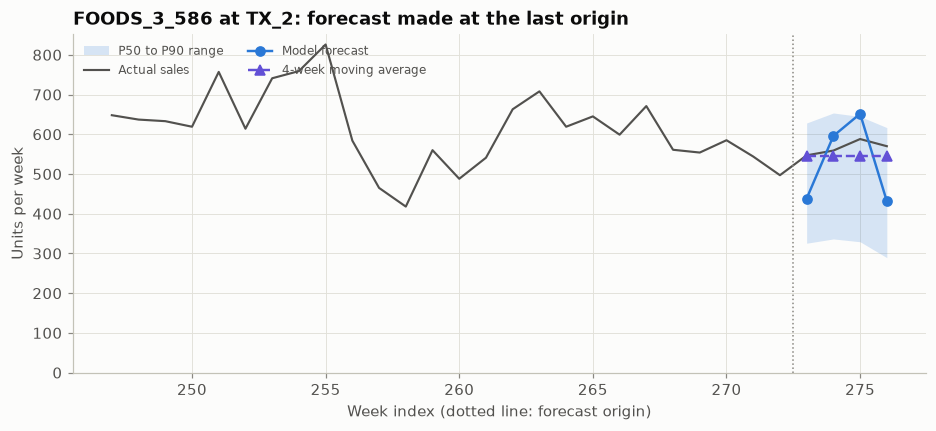

h,actual,hgbr,p50,p90,ma4,baseline_p90
1,547,438.200012,325.799988,628.400024,545.000000,644.099976
2,559,595.799988,336.600006,653.599976,545.000000,661.500000
3,588,651.599976,329.500000,644.900024,545.000000,680.900024
4,570,431.600006,289.500000,616.799988,545.000000,686.599976


In [12]:
df = add_week_index(pd.read_parquet(PROCESSED_DIR / "tx_weekly.parquet"))
last_origin = metrics["origins"][-1]["origin_idx"]
vol = df[df.store_id == "TX_2"].groupby("item_id", observed=True)["sales"].sum()
item, store = vol.idxmax(), "TX_2"

hist = df[(df.item_id == item) & (df.store_id == store) & (df.week_idx > last_origin - 26)]
f = fc[(fc.item_id == item) & (fc.store_id == store) & (fc.origin_idx == last_origin)].sort_values("h")

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(f["target_idx"], f["p50"], f["p90"], color=METHOD_COLORS["hgbr"], alpha=0.18,
                label="P50 to P90 range", linewidth=0)
ax.plot(hist["week_idx"], hist["sales"], color=INK_SECONDARY, linewidth=1.4, label="Actual sales")
ax.plot(f["target_idx"], f["hgbr"], color=METHOD_COLORS["hgbr"], marker="o", markersize=6, label="Model forecast")
ax.plot(f["target_idx"], f["ma4"], color=METHOD_COLORS["ma4"], marker="^", markersize=6,
        linestyle="--", label="4-week moving average")
ax.axvline(last_origin + 0.5, color=MUTED, linestyle=":", linewidth=1)
ax.set_title(f"{item} at {store}: forecast made at the last origin")
ax.set_xlabel("Week index (dotted line: forecast origin)")
ax.set_ylabel("Units per week")
ax.set_ylim(bottom=0)
ax.legend(loc="upper left", fontsize=8, ncols=2)
plt.show()

f[["h", "actual", "hgbr", "p50", "p90", "ma4", "baseline_p90"]].round(1).style.hide(axis="index")

**Reading it:** this top seller shows the weakness from section 1b. Its recent sales fall in HGBR's top bin, so the four horizon models land on different, partly arbitrary levels (the zigzag), and the P50 sits well below recent sales. For an item like this, the moving average is the better forecast today. For most items, the model is.

## 7. What this means and what's next

- **For a planner:**
  - Department totals are clearly more accurate with the model.
  - Stocking to the model's P90 delivers the same service with less inventory.
  - At single-item level, the model is about as good as a 4-week average for point forecasts. Its value there is the calibrated P90, not a sharper point estimate.
- **Honest limits:**
  - One spring of test weeks.
  - Sales instead of true demand.
  - Summed weekly P90s.
  - Default hyperparameters.
- **Candidates after the MVP:**
  - **First:** a scale-free target for HGBR (sales relative to each series' own level), to fix the top-seller weakness in section 1b.
  - A small, documented search over HGBR iterations and learning rate.
  - An item-level encoding for HGBR.
  - Testing across a holiday period.